# Machine Learning Project

## Miopia Dataset

We start by importing the dependencies for the project and analyzing the data

In [62]:
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

X_t = pd.read_csv("data/X_train.csv")
Y_t = pd.read_csv("data/Y_train.csv")

We now see the variables in the dataset

In [43]:
X_t.head()

,fecha,edad,sexo,origen antepasados (españa),origen antepasados (extranjeros),hº deporte sem,hº naturaleza sem,hº ocio exteriores sem,horas exterior sem,hº estudiar sem,...,OS-DS,CUVAF-Total,CUVAF-Media,CUVAF-DS,Promedio Nasal,DE Nasal,Suma Nasal,Promedio Temporal,DE Temporal,Suma Temporal
0,2/11/20,22,Mujer,Asturias,NaN,0.0,0.0,4.0,4.0,40,...,0.238059,2.256667,0.564167,0.842300,0.905000,1.279863,1.810000,0.223333,0.160278,0.446667
1,2/17/20,23,Mujer,Navarra,NaN,5.0,2.0,2.0,9.0,20,...,2.585654,8.026667,2.006667,1.887316,3.620833,0.503224,7.241667,0.392500,0.102530,0.785000
2,3/10/20,22,Mujer,Bizkaia,NaN,2.0,3.0,8.0,13.0,30,...,0.431335,12.710000,3.177500,0.743668,3.152500,1.248043,6.305000,3.202500,0.314663,6.405000
3,2/26/20,22,Mujer,"Navarra, Extremadura, Cataluña, Aragón",España,0.0,2.0,13.0,15.0,54,...,0.626968,3.551667,0.887917,0.877145,1.003333,1.418928,2.006667,0.772500,0.491439,1.545000
4,2/19/20,23,Mujer,Toledo,NaN,3.0,0.0,0.0,3.0,56,...,1.269257,1.795000,0.448750,0.897500,0.897500,1.269257,1.795000,0.000000,0.000000,0.000000


In [44]:
Y_t.head()

,M,MM,Combo,DCombo
0,SI,SI,MM,MM
1,SI,NO,M,M1
2,NO,NO,C,C
3,NO,NO,C,C
4,NO,NO,C,C


In [45]:
list(X_t.columns)

['fecha',
 'edad',
 'sexo',
 'origen antepasados (españa)',
 'origen antepasados (extranjeros)',
 'hº deporte sem',
 'hº naturaleza sem',
 'hº ocio exteriores sem',
 'horas exterior sem',
 'hº estudiar sem',
 'hº ocio inter sem',
 'hº act.cerca sem',
 'horas interior sem',
 'Ratio Cerca/Lejos',
 'Exterior Mucho',
 'Interior Mcho',
 'fototipo',
 'Grupo fot',
 'familiar miope',
 'Familiar miope num.',
 'Familiar MM SI/NO',
 'familiar miope magno',
 'pat. Ret. Miop magna',
 'fumador',
 'toma sol',
 'protege sol',
 'disp.elec.antes dormir',
 'LA OD',
 'LA OS',
 'LA Media',
 'Querato OD',
 'Querato OD Eje2',
 'Querato OS',
 'Querato OS Eje 2',
 'OD-Total',
 'OD-Media',
 'OD-DS',
 'OS-Total',
 'OS-Media',
 'OS-DS',
 'CUVAF-Total',
 'CUVAF-Media',
 'CUVAF-DS',
 'Promedio Nasal',
 'DE Nasal',
 'Suma Nasal',
 'Promedio Temporal',
 'DE Temporal',
 'Suma Temporal']

We start by seeing that in the X_train part of the data there are some columns which can be dropped, since they can be considered redundant for the analysis we want to make.

First, the 'fecha' column is the date of the test. As this is a tracking value for the test itself it doesn't influence in the data and could even lead to some false correlations

In [46]:
X_t.drop(columns=["fecha"], inplace=True)

/var/folders/j_/csb44tdj46q5z7vld9q7xss80000gn/T/ipykernel_61695/975913180.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  X_t.drop(columns=["fecha"], inplace=True)


We now try to see if we can discard some of the other columns

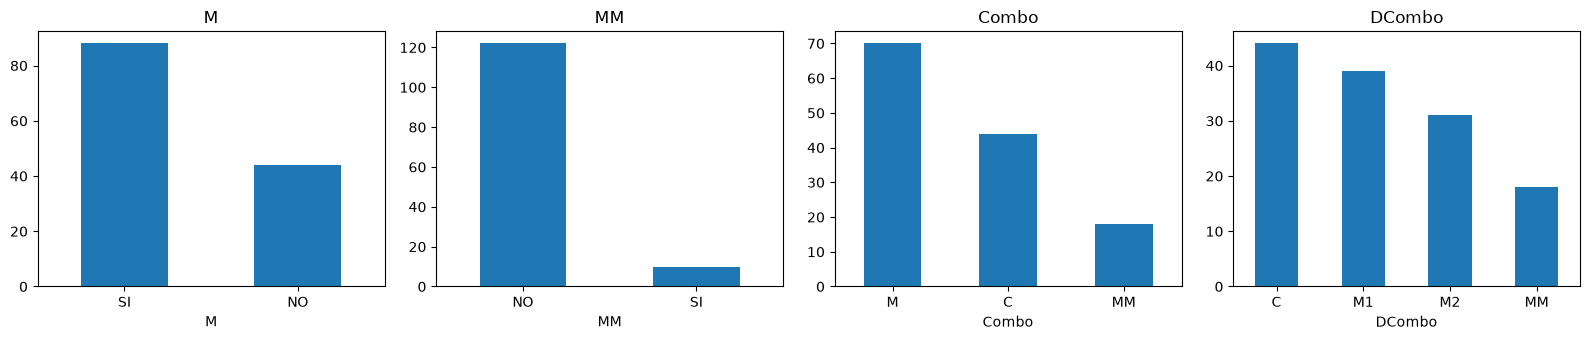

In [26]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, col in zip(axes, Y_t.columns):
    Y_t[col].value_counts().plot.bar(ax=ax, title=col, rot=0)
plt.tight_layout()

def heat(ct, ax, title):
    ax.imshow(ct.values, cmap='Blues')
    ax.set_xticks(range(ct.shape[1])); ax.set_xticklabels(ct.columns)
    ax.set_yticks(range(ct.shape[0])); ax.set_yticklabels(ct.index)
    for i in range(ct.shape[0]):
        for j in range(ct.shape[1]):
            ax.text(j, i, ct.values[i, j], ha='center', va='center')
    ax.set_title(title)

In [ ]:
X_t['hº act.cerca sem'].head()


0   NaN
1   NaN
2   NaN
3   NaN
4   NaN
Name: hº act.cerca sem, dtype: float64

In [47]:
X_t.drop(columns=["hº act.cerca sem"], inplace=True)

/var/folders/j_/csb44tdj46q5z7vld9q7xss80000gn/T/ipykernel_61695/236117783.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  X_t.drop(columns=["hº act.cerca sem"], inplace=True)


In [53]:
num_cols = X_t.select_dtypes('number').columns.tolist()
cont_cols = [c for c in num_cols if X_t[c].nunique() > 5]          # continuous-like
cat_cols = [c for c in X_t.columns if c not in cont_cols]          # categorical / binary / low-cardinality

# groups for later plots (keeps only columns that exist)
hours = [c for c in ['hº deporte sem', 'hº naturaleza sem', 'hº ocio exteriores sem',
                     'hº estudiar sem', 'hº ocio inter sem', 'horas exterior sem',
                     'horas interior sem', 'Ratio Cerca/Lejos'] if c in X_t]
biometry = [c for c in ['LA OD', 'LA OS', 'LA Media', 'Querato OD', 'Querato OS'] if c in X_t]

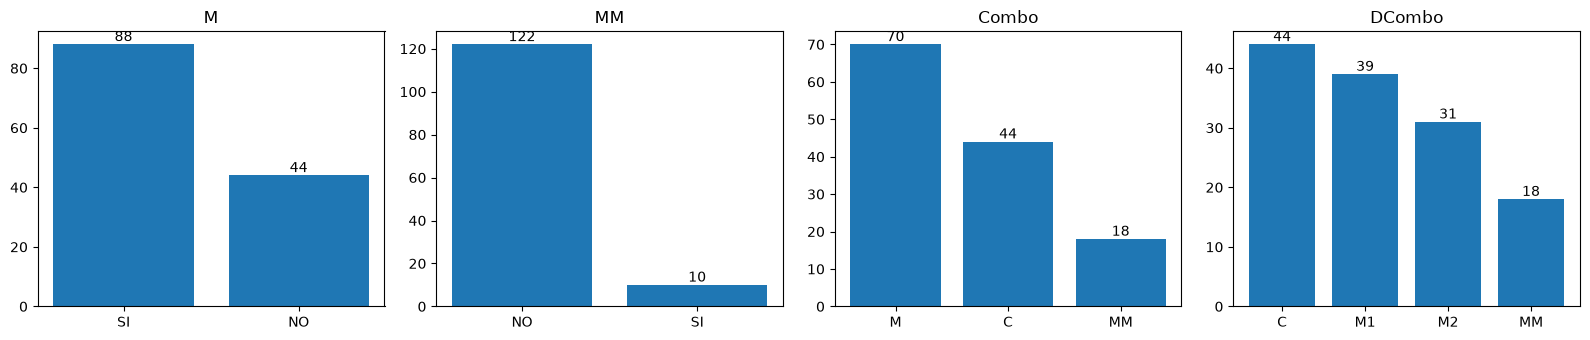

In [55]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, col in zip(axes, Y_t.columns):
    vc = Y_t[col].value_counts()
    ax.bar(vc.index.astype(str), vc.values)
    for i, v in enumerate(vc.values):
        ax.text(i, v, v, ha='center', va='bottom')
    ax.set_title(col)
plt.tight_layout()
plt.show()

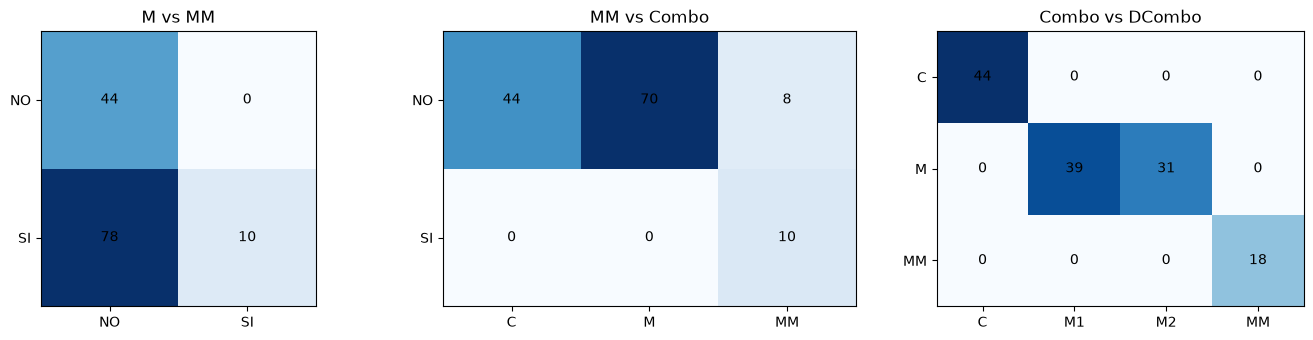

In [57]:
def heat(ct, ax, title):
    ax.imshow(ct.values, cmap='Blues')
    ax.set_xticks(range(ct.shape[1])); ax.set_xticklabels(ct.columns)
    ax.set_yticks(range(ct.shape[0])); ax.set_yticklabels(ct.index)
    for i in range(ct.shape[0]):
        for j in range(ct.shape[1]):
            ax.text(j, i, ct.values[i, j], ha='center', va='center')
    ax.set_title(title)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
heat(pd.crosstab(Y_t['M'], Y_t['MM']), axes[0], 'M vs MM')
heat(pd.crosstab(Y_t['MM'], Y_t['Combo']), axes[1], 'MM vs Combo')
heat(pd.crosstab(Y_t['Combo'], Y_t['DCombo']), axes[2], 'Combo vs DCombo')
plt.tight_layout()
plt.show()

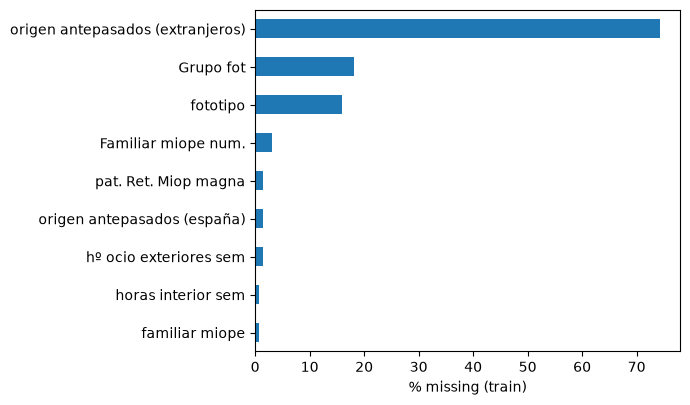

In [58]:
miss = (X_t.isna().mean() * 100).sort_values()
miss = miss[miss > 0]
ax = miss.plot.barh(figsize=(7, 0.35 * len(miss) + 1))
ax.set_xlabel('% missing (train)')
plt.tight_layout()
plt.show()

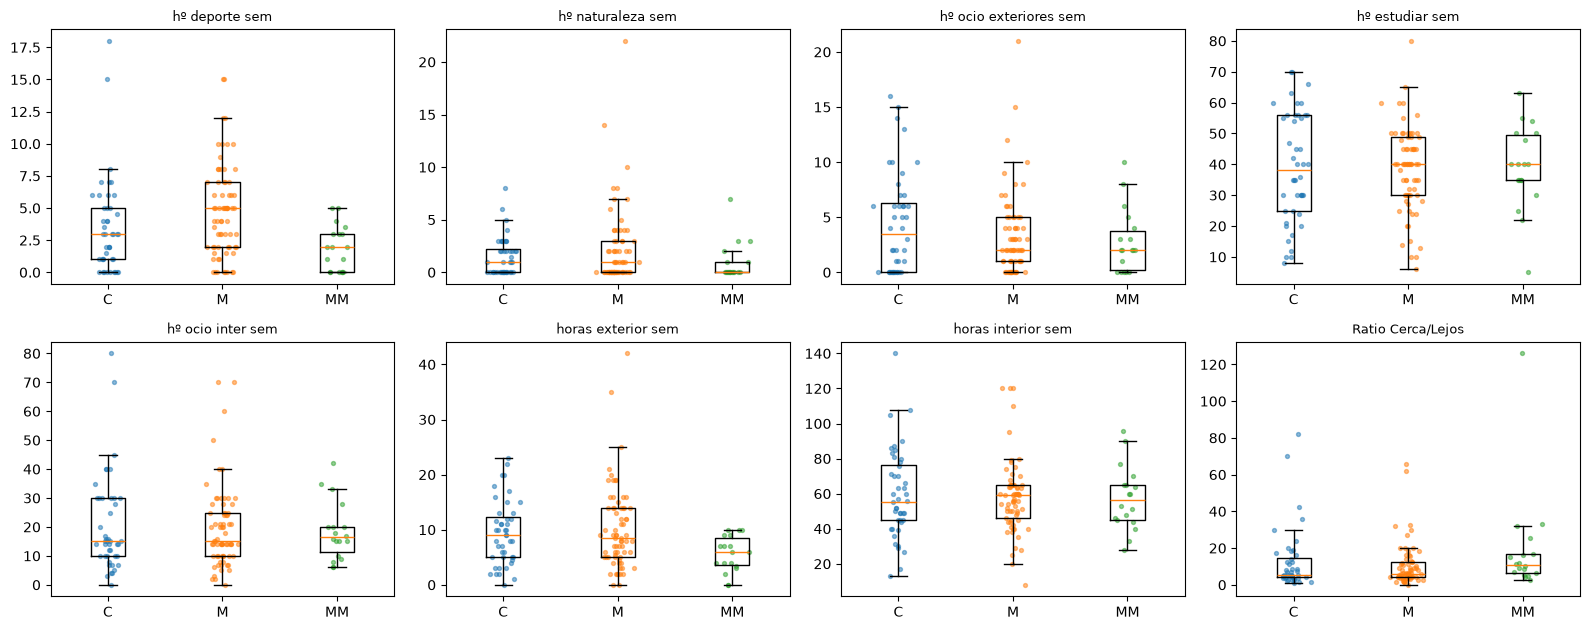

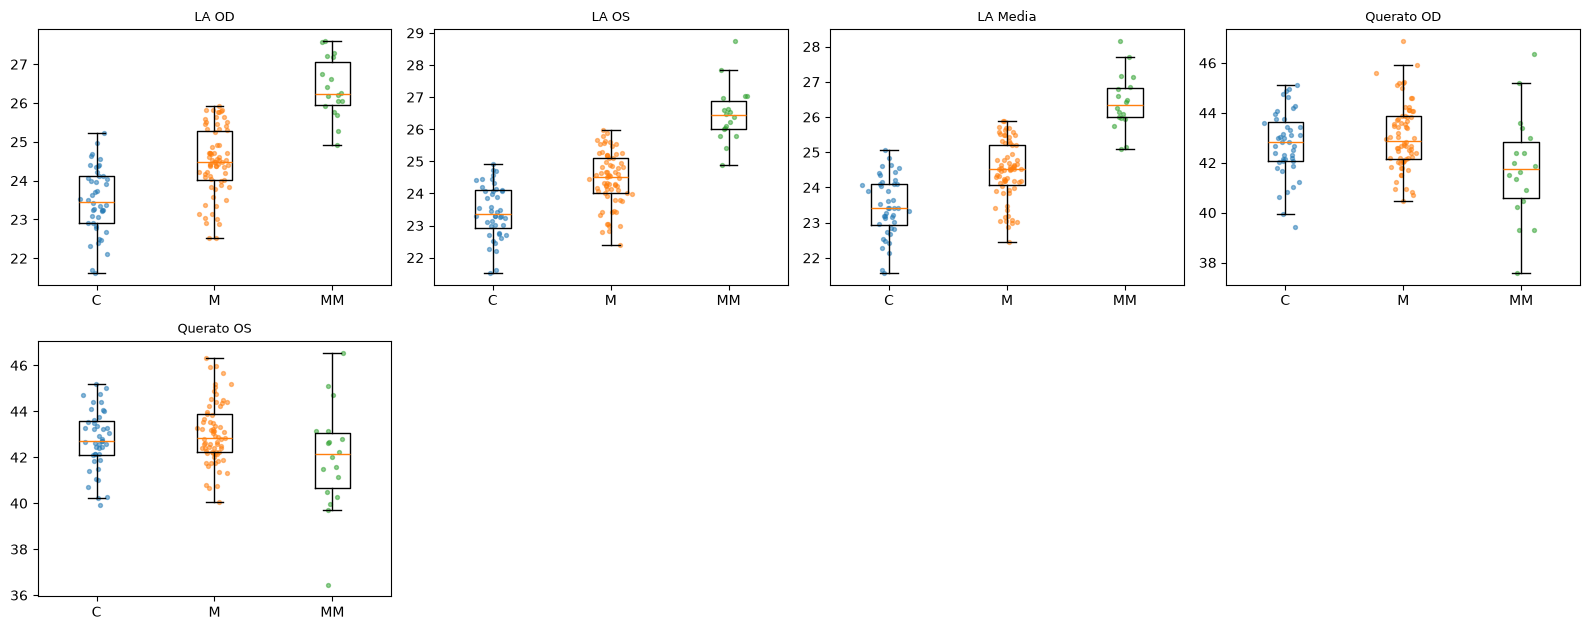

In [59]:
def box_by_class(cols, target, order, ncols=4):
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3.2 * nrows))
    axes = np.atleast_1d(axes).ravel()
    rng = np.random.default_rng(0)
    for ax, c in zip(axes, cols):
        data = [X_t.loc[Y_t[target] == k, c].dropna() for k in order]
        ax.boxplot(data, showfliers=False)
        for i, d in enumerate(data, start=1):
            ax.scatter(rng.normal(i, 0.06, len(d)), d, s=8, alpha=0.5)
        ax.set_xticks(range(1, len(order) + 1))
        ax.set_xticklabels(order)
        ax.set_title(c, fontsize=9)
    for ax in axes[len(cols):]:
        ax.axis('off')
    plt.tight_layout()
    plt.show()

box_by_class(hours, 'Combo', ['C', 'M', 'MM'])
box_by_class(biometry, 'Combo', ['C', 'M', 'MM'])

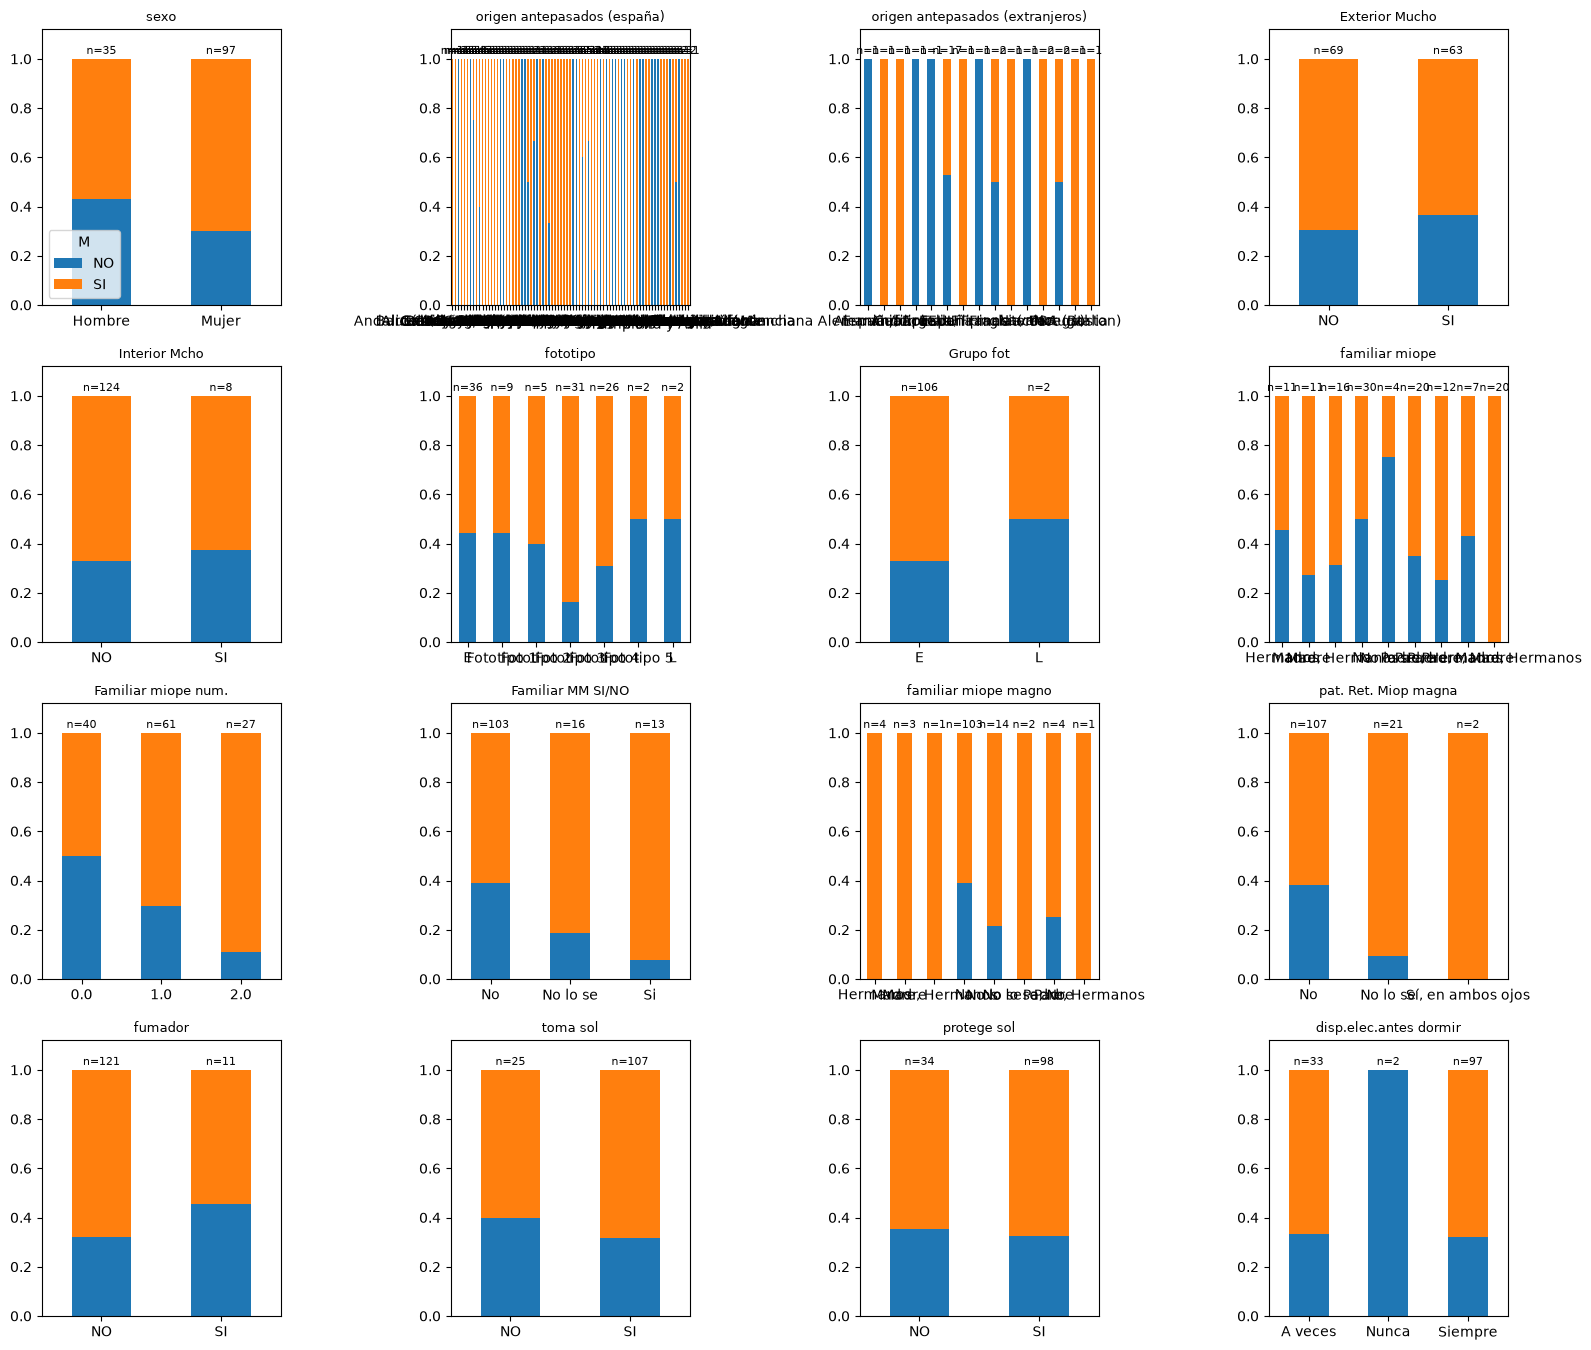

In [60]:
def prop_bars(cols, target='M', ncols=4):
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3.4 * nrows))
    axes = np.atleast_1d(axes).ravel()
    for k, (ax, c) in enumerate(zip(axes, cols)):
        ct = pd.crosstab(X_t[c], Y_t[target])
        prop = ct.div(ct.sum(axis=1), axis=0)
        prop.plot.bar(stacked=True, ax=ax, legend=(k == 0), rot=0)
        for i, n in enumerate(ct.sum(axis=1)):
            ax.text(i, 1.02, f'n={n}', ha='center', fontsize=8)
        ax.set_title(c, fontsize=9)
        ax.set_xlabel('')
        ax.set_ylim(0, 1.12)
    for ax in axes[len(cols):]:
        ax.axis('off')
    plt.tight_layout()
    plt.show()

prop_bars(cat_cols, target='M')

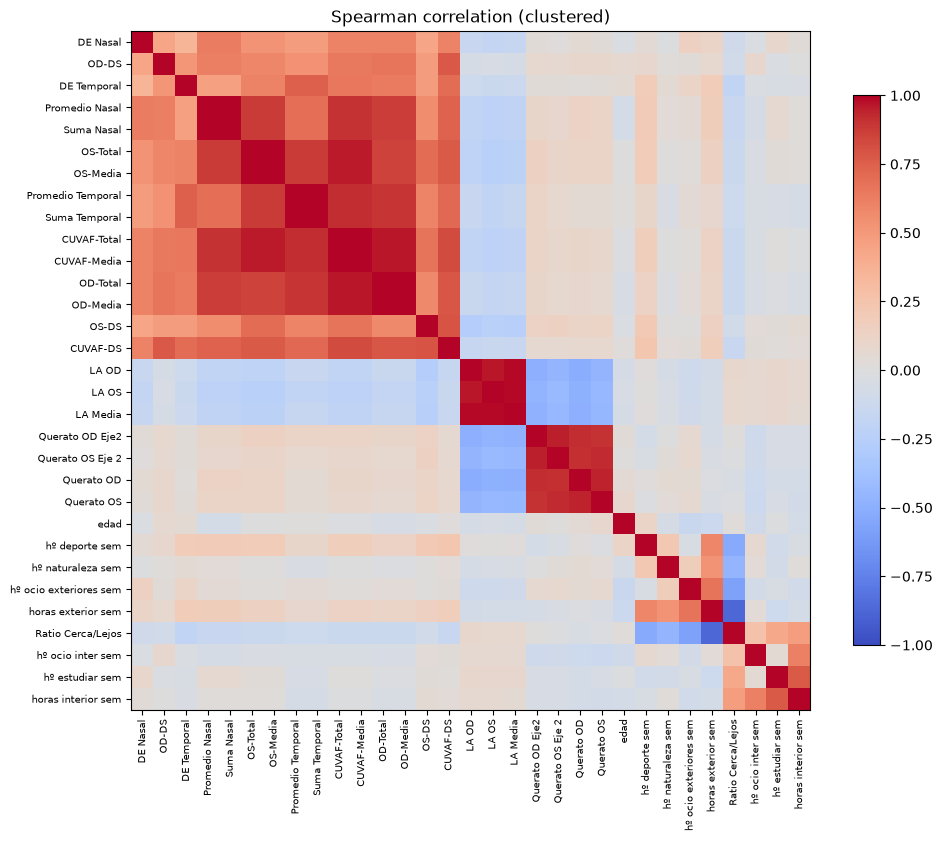

In [65]:
from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.spatial.distance import squareform

corr = X_t[cont_cols].corr(method='spearman')
d = (1 - corr.abs()).fillna(1).to_numpy(copy=True)   # writable copy
np.fill_diagonal(d, 0)
d = (d + d.T) / 2
order = leaves_list(linkage(squareform(d, checks=False), 'average'))
corr = corr.iloc[order, order]

fig, ax = plt.subplots(figsize=(10, 9))
im = ax.imshow(corr.values, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=90, fontsize=7)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns, fontsize=7)
fig.colorbar(im, ax=ax, shrink=0.7)
ax.set_title('Spearman correlation (clustered)')
plt.tight_layout()
plt.show()

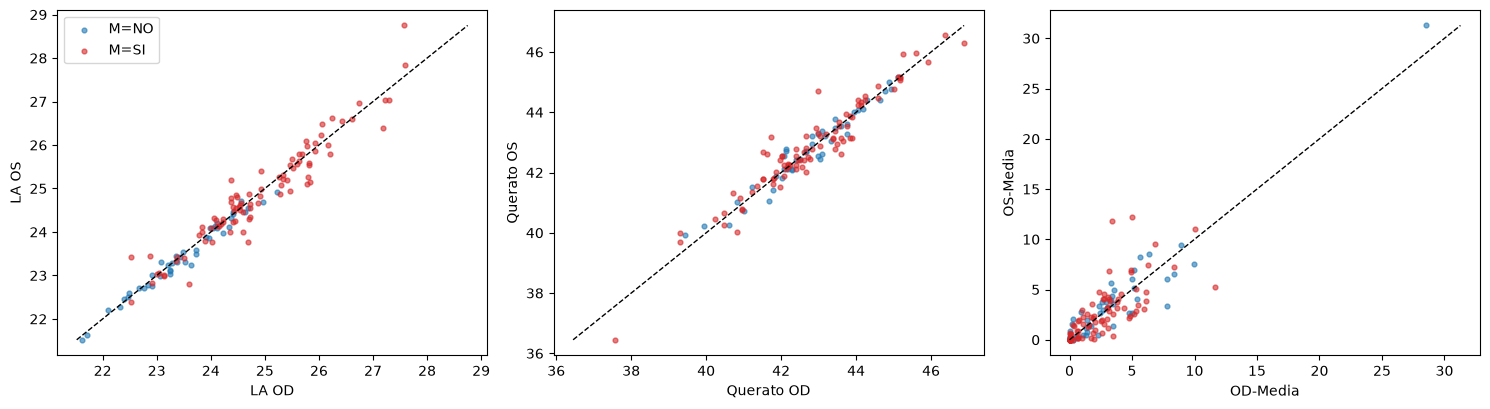

In [68]:
pairs = [('LA OD', 'LA OS'), ('Querato OD', 'Querato OS'), ('OD-Media', 'OS-Media')]
pairs = [p for p in pairs if p[0] in X_t and p[1] in X_t]

fig, axes = plt.subplots(1, len(pairs), figsize=(5 * len(pairs), 4.2))
axes = np.atleast_1d(axes)
for ax, (a, b) in zip(axes, pairs):
    for lab, color in [('NO', 'tab:blue'), ('SI', 'tab:red')]:
        m = Y_t['M'] == lab
        ax.scatter(X_t.loc[m, a], X_t.loc[m, b], s=12, alpha=0.6, c=color, label=f'M={lab}')
    lo = min(X_t[a].min(), X_t[b].min()); hi = max(X_t[a].max(), X_t[b].max())
    ax.plot([lo, hi], [lo, hi], 'k--', lw=1)
    ax.set_xlabel(a); ax.set_ylabel(b)
axes[0].legend()
plt.tight_layout()
plt.show()

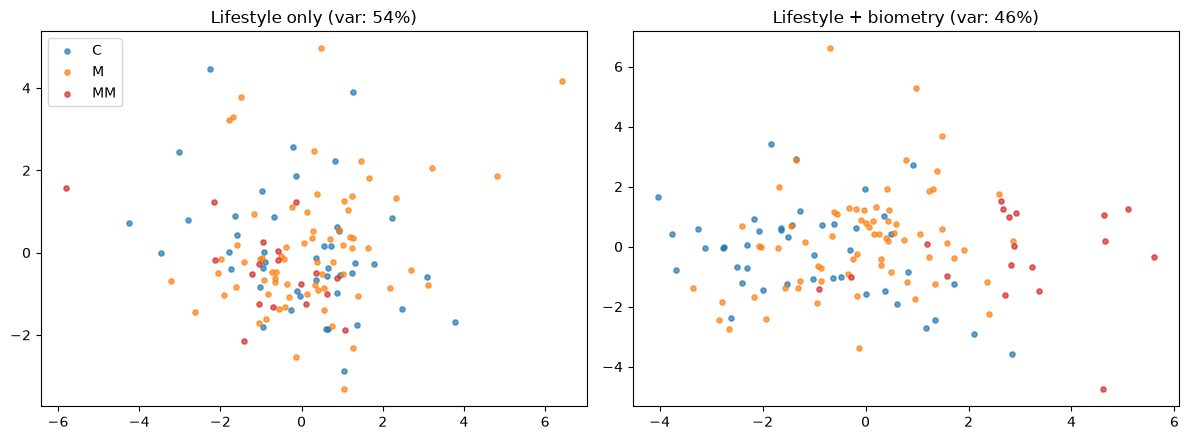

In [69]:
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

def pca_plot(cols, ax, title):
    Z = make_pipeline(SimpleImputer(strategy='median'), StandardScaler()).fit_transform(X_t[cols])
    pca = PCA(n_components=2).fit(Z)
    P = pca.transform(Z)
    for lab, color in [('C', 'tab:blue'), ('M', 'tab:orange'), ('MM', 'tab:red')]:
        m = (Y_t['Combo'] == lab).values
        ax.scatter(P[m, 0], P[m, 1], s=14, alpha=0.7, c=color, label=lab)
    ax.set_title(f'{title} (var: {pca.explained_variance_ratio_.sum():.0%})')

lifestyle_num = [c for c in hours if c in cont_cols] + [c for c in ['edad'] if c in cont_cols]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
pca_plot(lifestyle_num, axes[0], 'Lifestyle only')
pca_plot(lifestyle_num + biometry, axes[1], 'Lifestyle + biometry')
axes[0].legend()
plt.tight_layout()
plt.show()

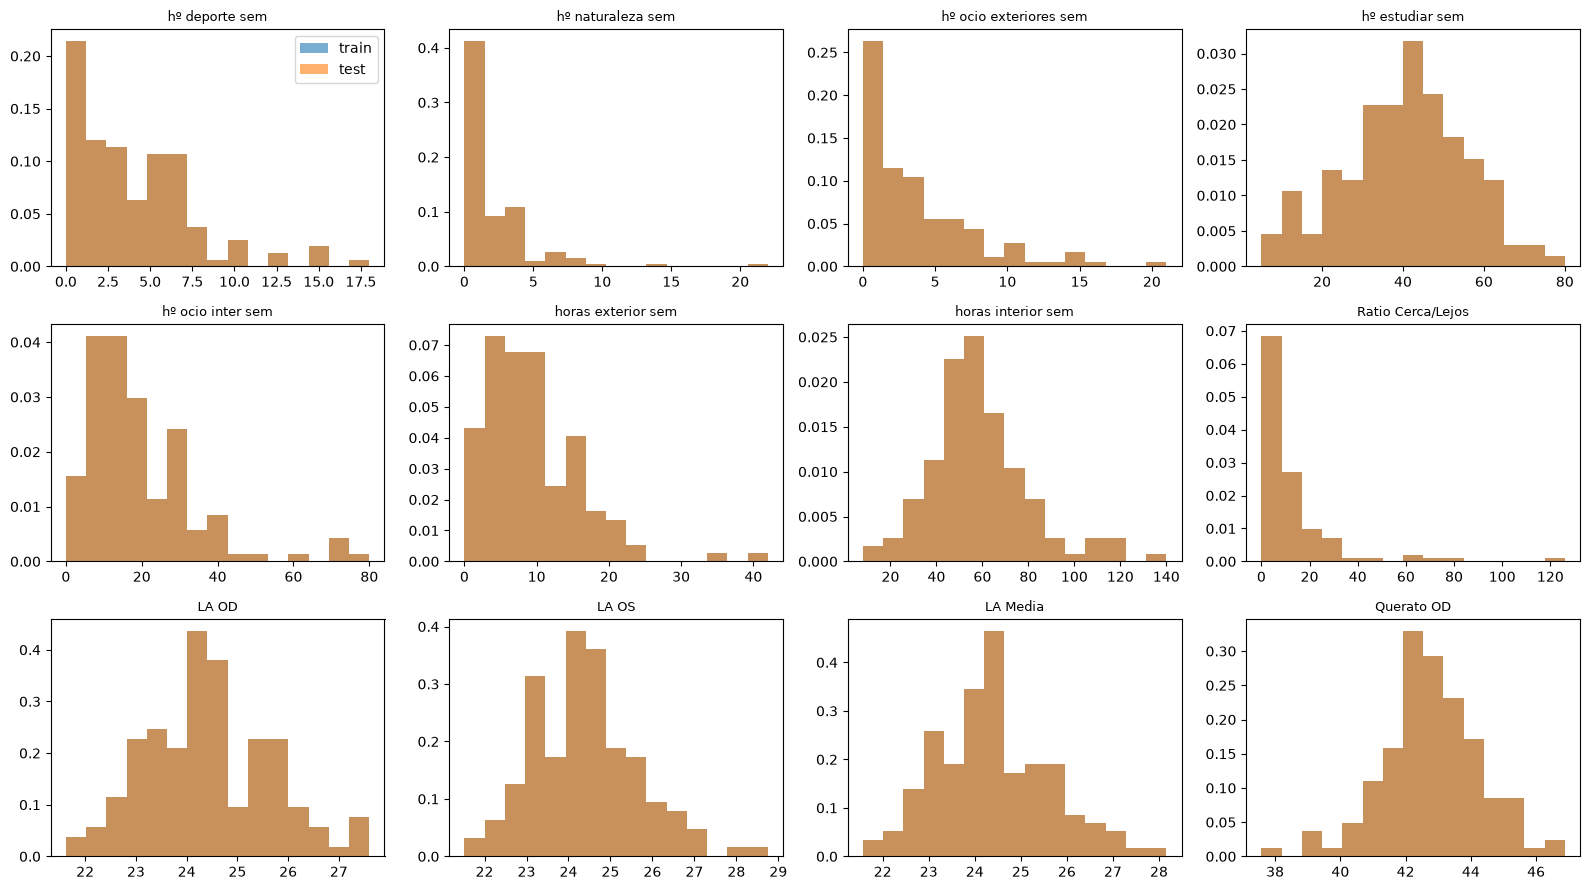

In [71]:
cols = (hours + biometry)[:12]
ncols = 4
nrows = int(np.ceil(len(cols) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3 * nrows))
axes = np.atleast_1d(axes).ravel()
for ax, c in zip(axes, cols):
    bins = np.histogram_bin_edges(pd.concat([X_t[c], X_t[c]]).dropna(), bins=15)
    ax.hist(X_t[c].dropna(), bins=bins, alpha=0.6, density=True, label='train')
    ax.hist(X_t[c].dropna(), bins=bins, alpha=0.6, density=True, label='test')
    ax.set_title(c, fontsize=9)
axes[0].legend()
for ax in axes[len(cols):]:
    ax.axis('off')
plt.tight_layout()
plt.show()